In [186]:
import keras_ocr
from tensorflow import keras
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib import transforms
import cv2

from PIL import Image
import numpy as np
import random
import tensorflow_probability as tfp

from sklearn.linear_model import LinearRegression

import math

In [2]:
import keras_cv

Using TensorFlow backend


C:\Users\sures\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
image_file = "Images/image_50402305.JPG"

In [4]:
tf_img = tf.io.read_file("Images/image_50402305.JPG")
tf_img = tf.image.decode_jpeg(tf_img, 1)

In [5]:
pipeline = keras_ocr.pipeline.Pipeline()

images = [keras_ocr.tools.read("Images/image_50402305.JPG")]

prediction_groups = pipeline.recognize(images) # Note that an image from the directory can be passed here

Looking for C:\Users\sures\.keras-ocr\craft_mlt_25k.h5

Instructions for updating:
Use `tf.image.resize(...method=ResizeMethod.BILINEAR...)` instead.

Looking for C:\Users\sures\.keras-ocr\crnn_kurapan.h5
8/8 [==============================] - 31s 3s/step


In [6]:
prediction_groups = prediction_groups[0]

---

In [7]:
# Define functions for dealing with images

image_width = 512 # 128
image_height = 128 # 32

def GetBox(Pred):
    x_max = 0
    x_min = 10000
    y_max = 0
    y_min = 10000

    for i in Pred[1]:
        x_max = max(i[0], x_max)
        x_min = min(i[0], x_min)
        y_max = max(i[1], y_max)
        y_min = min(i[1], y_min)

    # Each of these 4 variables is an edge of the box
    
    return x_max, x_min, y_max, y_min

def distortion_free_resize(image, img_size):
    w, h = img_size
    image = tf.image.resize(image, size=(h, w), preserve_aspect_ratio=True)

    # Check tha amount of padding needed to be done.
    pad_height = h - tf.shape(image)[0]
    pad_width = w - tf.shape(image)[1]

    # Only necessary if you want to do same amount of padding on both sides.
    if pad_height % 2 != 0:
        height = pad_height // 2
        pad_height_top = height + 1
        pad_height_bottom = height
    else:
        pad_height_top = pad_height_bottom = pad_height // 2

    if pad_width % 2 != 0:
        width = pad_width // 2
        pad_width_left = width + 1
        pad_width_right = width
    else:
        pad_width_left = pad_width_right = pad_width // 2

    image = tf.pad(
        image,
        paddings=[
            [pad_height_top, pad_height_bottom],
            [pad_width_left, pad_width_right],
            [0, 0],
        ],
    )

    image = tf.transpose(image, perm=[1, 0, 2])
    image = tf.image.flip_left_right(image)
    return image

def preprocess_image(image, img_size=(image_width, image_height)):
    image = distortion_free_resize(image, img_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image

def DisplayWord(word):
    word = tf.reshape(word, (image_width, image_height, 1))
    
    word = tf.image.flip_left_right(word)
    word = tf.transpose(word, perm=[1, 0, 2])
    # word = (word * 255.0).numpy().clip(0, 255).astype(np.uint8)

    plt.imshow(word[:, :, 0], cmap='gray')
    plt.show()

def WordBox(Pred):
    x_max, x_min, y_max, y_min = GetBox(Pred)

    print("The word is identified as: ", Pred[0])

    print(int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    word = tf.image.crop_to_bounding_box(tf_img, int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    return preprocess_image(word) # This returns a tensorflow image object

The word is identified as:  eunaleace
638 572 81 256


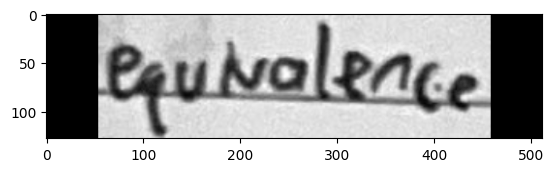

In [287]:
res = WordBox(prediction_groups[66])
DisplayWord(res)

In [288]:
word = res # This will be processed in the below code

# Pre-processing

In [289]:
from skimage.morphology import medial_axis, skeletonize, thin

from skimage.util import invert
import skimage

Make the image black background on white

In [290]:
def BgChange(word, CleaningCoefficient):

    # The higher the CleaningCoefficient, the more of the dimmer features that are cleaned out

    image = [ [ 0 for i in range(len(word[i])) ]  for i in range(len(word))]

    for i in range(len(word)):
        for j in range(len(word[i])):
            # if word[i][j][0] > 0.6:
            #     tf.print(word[i][j][0])
            #     image[i][j] = [1]
            # else:
            #     image[i][j] = [0]

            temp = float(word[i][j][0]) * CleaningCoefficient

            if temp == 0:
                temp = 1

            if temp > 1:
                temp = 1

            image[i][j] = temp

    image = tf.constant(image)

    image = skimage.img_as_float(image)
    image = invert(image)

    DisplayWord(image)

    return image

In [291]:
def BgChangeOptimised(word, CleaningCoefficient):
    word = word * CleaningCoefficient

    word = tf.constant(np.where(word == 0, 1, word))

    word = tf.where(word > 1, 1, word)

    word = skimage.img_as_float(word)
    word = invert(word)

    DisplayWord(word)

    return tf.constant(word)
    

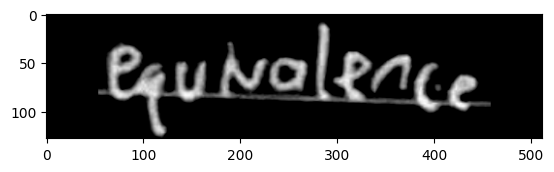

In [292]:
image = BgChangeOptimised(word, 2)

Remove Line (hasn't worked out as of yet)

In [199]:
# A = BgChange(word, 1.5)
# B = BgChange(word, 3)

# C = A - 2 * B

# DisplayWord(C)



In [200]:
line_thickness=2

img = res

# Apply binary thresholding to get a binary image
binary_image = tf.where(img < 0.5, 0.0, 1.0)

# Create a horizontal kernel
kernel = tf.ones((1, line_thickness, 1, 1), dtype=tf.float32)

# Apply 1D convolution to detect horizontal lines
lines_detected = tf.nn.conv2d(binary_image[None, ..., None], kernel, strides=[1, 1, 1, 1], padding='SAME')[0, ..., 0]

# Set pixels corresponding to detected lines to 0
result_image = tf.where(lines_detected > 0, 0.0, img)


Slope removal

In [201]:
def RotateImage(image, angle):
    image = tf.reshape(image, [image_width,image_height])
    im = image.numpy()
    im = Image.fromarray(im)
    im_rotated = im.rotate(angle=angle)
    im = np.asarray(im_rotated)
    image_r = tf.convert_to_tensor(im)

    return image_r

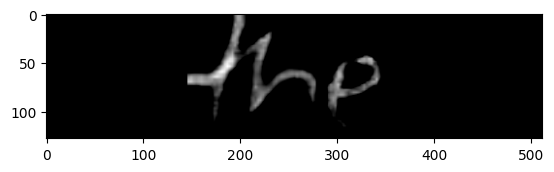

In [202]:
DisplayWord(image)

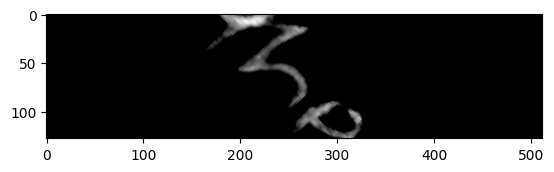

In [203]:
DisplayWord(RotateImage(image, -45))

In [204]:
def HorizontallHistorgram(image):
    image = tf.reshape(image, [image_width,image_height])
    sums = tf.map_fn(lambda x: tf.math.reduce_sum(x), image)
    return sums

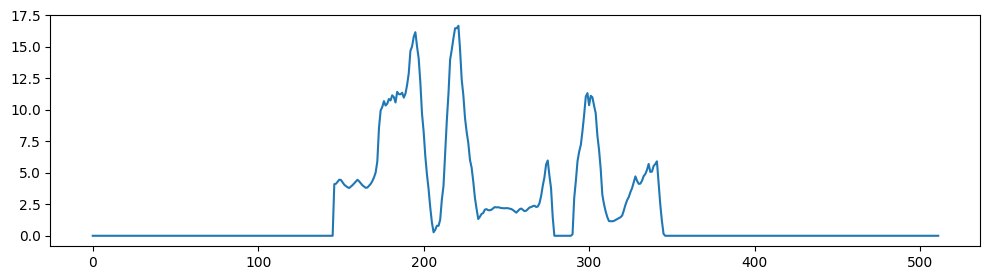

In [205]:
plt.figure(figsize=(12,3))
plt.plot(HorizontallHistorgram(image))

In [206]:
def VerticalHistorgram(image):
    image = tf.reshape(image, [image_width,image_height])
    sums = tf.reduce_sum(image, axis=0)
    return sums

In [207]:
VerticalHistorgram(image)

<tf.Tensor: shape=(128,), dtype=float32, numpy=
array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.06643599,  0.19892538,  0.14396787,  0.14338928,
        0.06274283,  0.06469923,  0.165528  ,  0.07537949,  0.08452225,
        0.11889809,  0.21152174,  0.434313  ,  0.5630092 ,  0.6593493 ,
        0.7448101 ,  0.7218756 ,  1.0357597 ,  1.5756221 ,  2.1931088 ,
        3.0283132 ,  3.460473  ,  3.9500828 ,  4.575843  ,  4.9572544 ,
        5.444081  ,  5.736435  ,  5.894351  ,  6.246919  ,  6.5412035 ,
        6.971367  ,  8.235109  ,  9.6244755 , 11.41365   , 12.933038  ,
       13.908094  , 15.504098  , 16.033436  , 16.60654   , 17.077034  ,
       15.224869  , 14.461306  , 14.480455  , 15.897582  , 20.99647   ,
       22.83776   , 24.588549  , 26.556181  , 26.358242  , 27.12655   ,
       28.401161  , 30.711618  , 33.794315  , 32.299713  , 30.04801   ,
       27.280167

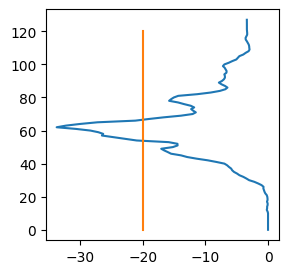

In [208]:
plt.figure(figsize=(3,3))
base = plt.gca().transData
rot = transforms.Affine2D().rotate_deg(90)

Vals = VerticalHistorgram(image)

plt.plot(Vals, transform = rot + base)

plt.plot([-20, -20], [-0, 120])

In [209]:
def GetVariance(Vals, threshold):
    below_threshold_mask = tf.math.less_equal(Vals, threshold)
    weight_below = tf.math.reduce_sum(tf.cast(below_threshold_mask, dtype=tf.float32))
    vals_below = tf.cast(below_threshold_mask, dtype=tf.float32) * Vals # These are the values below the threshold
    vals_below = tf.boolean_mask(vals_below, tf.math.logical_not(tf.math.equal(vals_below, 0))) # Remove the zeros
    variance_below_threshold = tf.math.reduce_variance(vals_below)

    above_threshold_mask = tf.math.greater(Vals, threshold)
    weight_above = tf.math.reduce_sum(tf.cast(above_threshold_mask, dtype=tf.float32))
    vals_above = tf.cast(above_threshold_mask, dtype=tf.float32) * Vals # These are the values above the threshold
    vals_above = tf.boolean_mask(vals_above, tf.math.logical_not(tf.math.equal(vals_above, 0))) # Remove the zeros
    variance_above_threshold = tf.math.reduce_variance(vals_above)

    weighted_variance = ( variance_above_threshold * weight_above + variance_below_threshold * weight_below ) / ( weight_above + weight_below )

    return weighted_variance

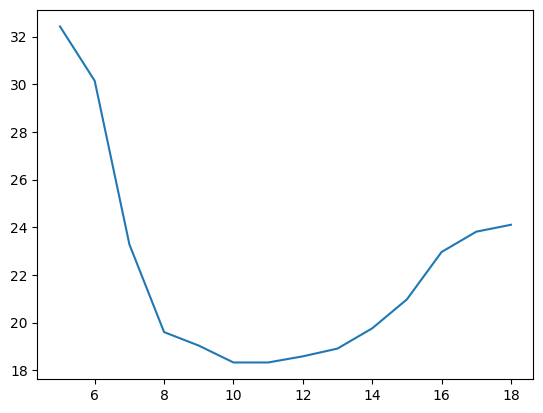

In [210]:
# Find the core region and the area of the image to be scanned

x = []
y = []

for i in range(5, int(tfp.stats.percentile(Vals, 90)), 1):
    x.append(i)

    y.append(GetVariance(Vals, i))

plt.plot(x, y)

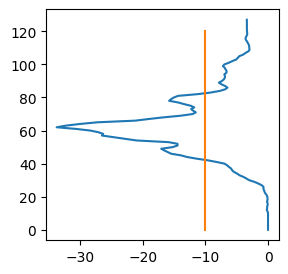

In [211]:
core_threshold = x[y.index(min(y))]

plt.figure(figsize=(3,3))
base = plt.gca().transData
rot = transforms.Affine2D().rotate_deg(90)

plt.plot(Vals, transform = rot + base)

plt.plot([-core_threshold, -core_threshold], [-0, 120])

In [212]:
above_threshold_mask = tf.math.greater(Vals, core_threshold)
locs = tf.where(above_threshold_mask)
core_region_base = int(locs[-1])
core_width = len(locs)

In [213]:
low_limit = int(core_region_base - 0.25 * core_width)
upper_limit = int(core_region_base + 0.25 * core_width)

In [214]:
for i in range(low_limit, upper_limit):
    print(i)

72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91


In [250]:
base = []

for column in range(len(image)):
    line = 0
    found = False # To reset
    index = 0
    val_max = 0 # To reset

    for i in range(low_limit, upper_limit):
        print(image[column][i])
        if image[column][i] != 0 and found == False:
            line += 1
            found = True
            if image[column][i] > val_max:
                index = i
                val_max = image[column][i]

        elif image[column][i] != 0 and found == True:
            if image[column][i] > val_max:
                index = i
                val_max = image[column][i]        

        elif image[column][i] == 0 and found == True:   
            found = False
            val_max = 0

    if image[column][upper_limit] == 0: # This prevents lines which extend below from being counted
        base.append(index)
    else:
        base.append(0)

print(base)

tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([0.], shape=(1,), dtype=float32)
tf.Tensor([

In [251]:
line = 0
found = False # To reset
index = 0
val_max = 0
val_max_list = []
val_max_indices = []

for i in range(len(base)):
    print(found)
    if base[i] != 0 and found == False:
        line += 1
        found = True
        if base[i] > val_max:
            index = i
            val_max = base[i]

    elif base[i] != 0 and found == True:
        if base[i] > val_max:
            index = i
            val_max = base[i]        

    elif base[i] == 0 and found == True:   
        found = False
        val_max_list.append(val_max)
        val_max_indices.append(index)
        val_max = 0

print(val_max_indices)
print(val_max_list)

val_max_indices = tf.reshape(tf.constant(val_max_indices), [len(val_max_indices),1])
val_max_list =  tf.reshape(tf.constant(val_max_list), [len(val_max_list),1])

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
Fals

In [252]:
line = LinearRegression().fit(val_max_indices, val_max_list)

In [253]:
rotate = - math.atan(line.coef_[0][0]) * 180 / math.pi
image = RotateImage(image, rotate)

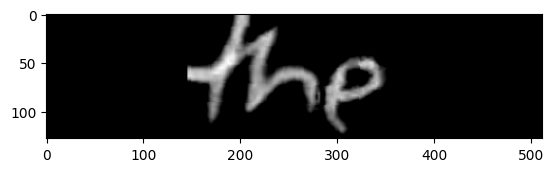

In [254]:
DisplayWord(image)

Slant removal

In [256]:
def shear_image(image, angle):
    """
    Shear a TensorFlow image by a given angle.

    Parameters:
    - image: TensorFlow tensor, input image (batched or not)
    - angle: float, shear angle in radians

    Returns:
    - sheared_image: TensorFlow tensor, sheared image
    """
    # Get image shape
    image_shape = tf.shape(image)

    # Create shear matrix
    shear_matrix = tf.raw_ops.AffineWarpImage(
        images=tf.expand_dims(image, axis=0),  # Batch dimension
        transforms=tf.convert_to_tensor([[[np.cos(angle), -np.sin(angle), 0.0],
                                          [np.sin(angle), np.cos(angle), 0.0]]],
                                        dtype=tf.float32),
        output_shape=image_shape
    )

    # Extract the sheared image from the batch
    sheared_image = shear_matrix[0]

    return sheared_image

In [300]:
image = tf.reshape(image, [image_width, image_height])
image = tf.reshape(image, [1, image_width, image_height])


In [445]:
angle = 10
shear = tf.keras.preprocessing.image.apply_affine_transform(image, theta = angle, shear = -angle)

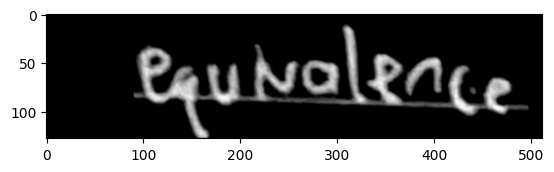

In [446]:
shear = tf.reshape(shear, [image_width, image_height])


DisplayWord(shear)

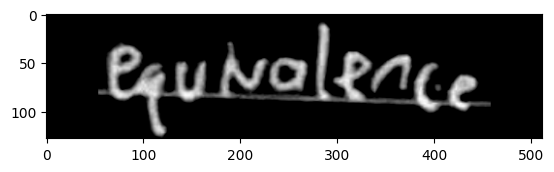

In [447]:
DisplayWord(image)

In [356]:
import tensorflow_addons as tfa

C:\Users\sures\AppData\Roaming\Python\Python311\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(
C:\Users\sures\AppData\Roaming\Python\Python311\site-packages\tensorflow_addons\utils\ensure_tf_install.py:53: UserWarning: Tensorflow Addons supports using Python ops for all Tensorflow versions above or equal to 2.12.0 and strictly below 2.15.0 (nightly versions are not supported). 
 The versions of TensorFlow you are currently using is 2.15.0 and is not supported. 
Some things might work, some things might not.
If you were to encounter a bug, do not file

In [363]:
def transformImg(imgIn,forward_transform):
    t = tfa.image.translations_to_projective_transforms(tf.linalg.inv(forward_transform))
    # please notice that forward_transform must be a float matrix,
    # e.g. [[2.0,0,0],[0,1.0,0],[0,0,1]] will work
    # but [[2,0,0],[0,1,0],[0,0,1]] will not
    imgOut = tfa.image.transform(imgIn, t, interpolation="BILINEAR",name=None)
    return imgOut

In [368]:
shear_lambda = 2
# shear = transformImg(image, [[1.0,shear_lambda,0],[0,1.0,0],[0,0,1.0]])
shear = transformImg(image, [[1.0, 2.0, 1.0, 2.0, 1.0]])
DisplayWord(shear)

InvalidArgumentError: {{function_node __wrapped__MatrixInverse_device_/job:localhost/replica:0/task:0/device:CPU:0}} Input is not invertible. [Op:MatrixInverse]

In [420]:
import skimage as ski

In [443]:
numpy_image = image.numpy()
image_sk = ski.exposure.equalize_hist(numpy_image)

In [444]:
tform = ski.transform.AffineTransform(
#    rotation=np.pi / 12.,
#    translation = (10, -20),
   shear=10
   )
shear = ski.transform.warp(image_sk, tform.inverse)

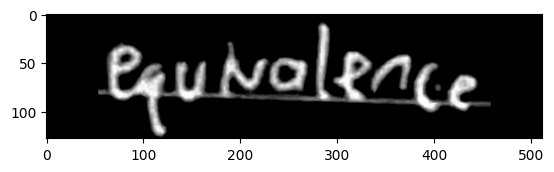

In [442]:
DisplayWord(tf.constant(shear))

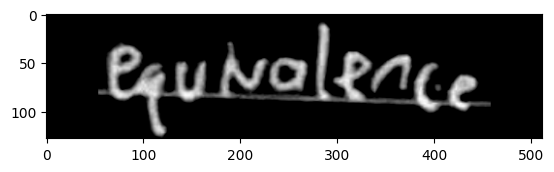

In [435]:
DisplayWord(image)

Make the characters 1 pixel wide

In [37]:
skeleton = thin(image, max_num_iter=1)

# or skeletonize(image)

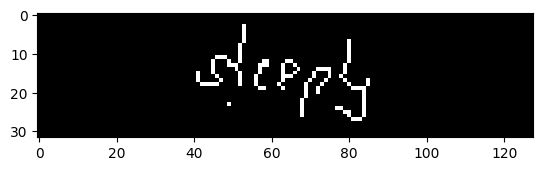

In [38]:
DisplayWord(skeleton)

In [39]:
skel, distance = medial_axis(image, return_distance=True)

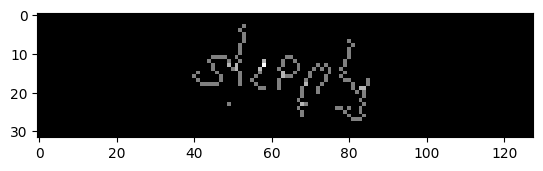

In [40]:
dist_on_skel = distance * skel
DisplayWord(dist_on_skel)

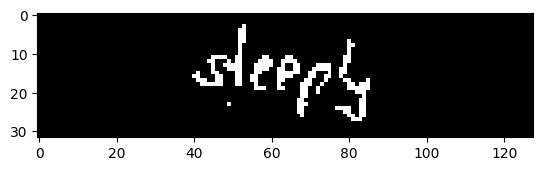

In [41]:
def convert_non_zero_to_one(tensor):
    # Create a boolean mask for non-zero values
    non_zero_mask = tf.math.not_equal(tensor, 0)
    
    # Convert non-zero values to 1 using the boolean mask
    result_tensor = tf.where(non_zero_mask, 1, tensor)
    
    return result_tensor

DisplayWord(convert_non_zero_to_one(image))